# 🌽 FoodFlow: Predicting Uganda Maize Prices
**Author:** Okecho Danmark Laston · BDSAI, Cavendish University

### The question
Can we predict **next month's maize price** in each Ugandan market, and spot **unusual** markets and months?

### The big idea (simple version)
A model is a student. We show it many past months (prices, season, place, other food prices). It learns the pattern. Then we ask: *"What will maize cost next month?"*

### What this notebook does
| Part | Type of learning | What it does |
|---|---|---|
| Forecast next month's price | **Supervised** | Learns from past answers |
| Price range (low to high) | **Supervised** (quantile) | Says how sure it is |
| Group similar markets | **Unsupervised** (K-means) | Finds groups with no answers given |
| Flag strange months | **Unsupervised** (anomaly) | Rings an alarm for shocks |

**Data:** WFP Uganda food prices (2006 to 2026, 43 markets), from the Humanitarian Data Exchange (HDX).
**Optional:** NASA POWER rain + temperature (downloads by itself when you have internet).

Run the cells from top to bottom (Shift + Enter). Each step says **why**, **how to check it worked**, and **what to do if it fails**.

## Step 1: Tools
💡 **Why:** `pandas` = spreadsheets in code, `numpy` = maths, `matplotlib` = charts, `scikit-learn` = models.

🔧 **If it fails:** `pip install pandas numpy matplotlib scikit-learn requests joblib`, then restart the notebook.

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

PRICE_FILE = "wfp_food_prices_uga.csv"
TRAIN_END  = "2023-12-01"   # train = up to here
VAL_END    = "2024-12-01"   # validation = 2024, test = 2025 onward
print("Tools ready ✅")

Tools ready ✅


## Step 2: Load the data
💡 **Why:** Look in the fridge before cooking. How big is it? What's inside?

✅ **Check:** about 32,000 rows, dates from 2006 to 2026.
🔧 **If it fails:** *FileNotFoundError* → put the CSV in the same folder as this notebook.

In [2]:
df = pd.read_csv(PRICE_FILE, skiprows=[1])        # row 2 is a note row, skip it
df["date"]  = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()

print("Rows, columns:", df.shape)
print("Dates:", df["date"].min().date(), "to", df["date"].max().date())
print("Markets:", df["market"].nunique())
df["commodity"].value_counts().head(10)

Rows, columns: (32291, 17)
Dates: 2006-01-15 to 2026-08-15
Markets: 43


commodity
Beans              3206
Maize flour        3115
Maize (white)      2822
Sorghum            2714
Oil (vegetable)    2595
Cassava flour      2164
Millet             1669
Salt                876
Millet flour        865
Cassava (fresh)     828
Name: count, dtype: int64

## Step 3: Clean the maize data
💡 **Why:** Dirty data = confused student. We fix four things:
1. **Maize flour ≠ maize grain** → keep grain only (`Maize (white)` and `Maize`)
2. **Retail ≠ wholesale** → keep retail only
3. **Mixed units** → keep price per KG only
4. **Impossible prices** → one row says 2 UGX/kg, a typing mistake → remove prices under 100

✅ **Check:** about 3,000 clean rows remain.

In [3]:
maize = df[df["commodity"].isin(["Maize (white)", "Maize"])]
print("Maize grain rows:      ", len(maize))
maize = maize[(maize["pricetype"] == "Retail") & (maize["unit"] == "KG")]
print("Retail, per KG:        ", len(maize))
print("Lowest prices:", sorted(maize["price"])[:5])
maize = maize[maize["price"] >= 100]
print("After removing mistakes:", len(maize))

Maize grain rows:       3553
Retail, per KG:         3009
Lowest prices: [2.0, 283.33, 300.0, 300.0, 333.33]
After removing mistakes: 3008


## Step 4: One price per market per month
💡 **Why:** Weather and seasons come as **monthly** numbers. So every row becomes **market + month + price**. This is the "matching key" we use to join other data.

We keep markets with at least **36 months** of history. A market with 5 data points teaches nothing.

Markets kept: 39 | rows: 2773


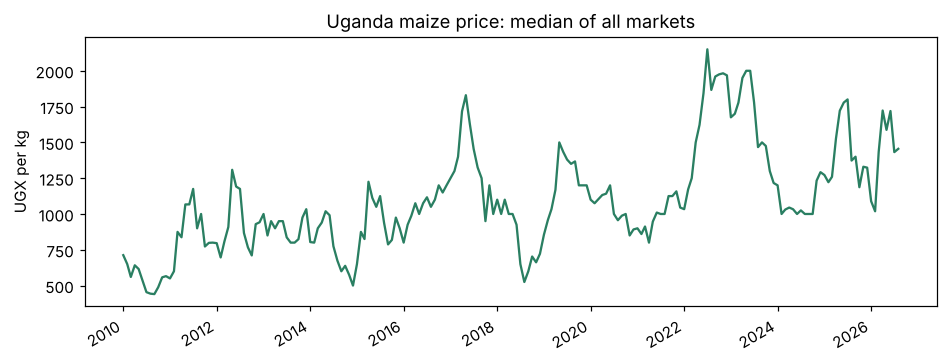

In [4]:
monthly = maize.groupby(["market", "latitude", "longitude", "month"], as_index=False)["price"].mean()
counts  = monthly.groupby("market")["month"].count()
monthly = monthly[monthly["market"].isin(counts[counts >= 36].index)]
print("Markets kept:", monthly["market"].nunique(), "| rows:", len(monthly))

fig, ax = plt.subplots(figsize=(10, 3.6))
monthly.groupby("month")["price"].median().plot(ax=ax, color="#2a7f62")
ax.set_title("Uganda maize price: median of all markets"); ax.set_ylabel("UGX per kg"); ax.set_xlabel("")
plt.show()

**What the chart tells us:** prices rose about 7× since 2006 (inflation), with yearly waves (harvest vs lean season) and a big spike in 2022–23. The model has to learn the **waves** and the **shocks**.

## Step 5: Fill the calendar gaps
💡 **Why:** For "last month's price" to really mean last month, every market needs a row for **every** month. Missing months become empty, not skipped.

In [5]:
full = []
for mk, g in monthly.groupby("market"):
    idx = pd.date_range(g["month"].min(), g["month"].max(), freq="MS")
    g = g.set_index("month").reindex(idx)
    g["market"] = mk
    g[["latitude", "longitude"]] = g[["latitude", "longitude"]].ffill().bfill()
    g.index.name = "month"
    full.append(g.reset_index())
panel = pd.concat(full).sort_values(["market", "month"]).reset_index(drop=True)
print("Rows with empty months included:", len(panel), "| empty prices:", panel["price"].isna().sum())

Rows with empty months included: 3331 | empty prices: 558


## Step 6: Add more clues from the same file
💡 **Why:** The WFP file has more than maize. Other food prices in the **same market** tell a story:
- **Maize flour** is made from maize, so it moves with it
- **Beans, sorghum** compete for the same shoppers and farms
- **National median price** shows if the whole country is getting pricier

This is "combining data to get more parameters" (your question): join tables on **market + month**.

In [6]:
for food, name in [("Maize flour", "flour"), ("Beans", "beans"), ("Sorghum", "sorghum")]:
    other = (df[(df["commodity"] == food) & (df["unit"] == "KG") & (df["pricetype"] == "Retail")]
             .groupby(["market", "month"])["price"].mean().rename(name + "_price").reset_index())
    panel = panel.merge(other, on=["market", "month"], how="left")

national = monthly.groupby("month")["price"].median().rename("national_price").reset_index()
panel = panel.merge(national, on="month", how="left")
panel[["market", "month", "price", "flour_price", "beans_price", "sorghum_price", "national_price"]].dropna().head()

,market,month,price,flour_price,beans_price,sorghum_price,national_price
0,Adjumani (refugee settlement),2020-12-01,1037.0,1758.0,3300.0,1333.0,892.0
1,Adjumani (refugee settlement),2021-01-01,1059.0,1913.0,3508.0,1219.0,900.0
2,Adjumani (refugee settlement),2021-02-01,1099.0,2150.0,3524.0,1159.0,860.0
3,Adjumani (refugee settlement),2021-03-01,1062.0,1733.0,3419.0,1338.0,912.5
5,Adjumani (refugee settlement),2021-05-01,944.0,1736.0,3120.0,1120.0,947.0


## Step 7 (optional): Rain + temperature from NASA POWER 🛰️
💡 **Why:** Rain and heat decide harvests, and harvests decide prices. NASA POWER is **free, with no account or key**. It gives monthly rain and temperature for each market's GPS point.

**How it works:** it tests the internet first. If NASA can be reached, it downloads (a few minutes the first time) and saves to `weather_cache/`. **If there's no internet, it skips safely** and the rest still works.

⚠️ NASA POWER rain is coarse (about 50 km squares). CHIRPS v3 is sharper and is a later upgrade.

🔧 **If it fails:** check your internet and re-run. It resumes from the cache.

In [7]:
weather_df = None
try:
    import requests
    START, END = int(monthly["month"].dt.year.min()), int(monthly["month"].dt.year.max())
    URL = "https://power.larc.nasa.gov/api/temporal/monthly/point"
    requests.get(URL, params={"parameters": "T2M", "community": "AG", "latitude": 0.3, "longitude": 32.5,
                              "start": 2020, "end": 2020, "format": "JSON"}, timeout=20).raise_for_status()
    os.makedirs("weather_cache", exist_ok=True)
    rows = []
    for _, p in monthly[["market", "latitude", "longitude"]].drop_duplicates("market").iterrows():
        path = f"weather_cache/{p.latitude:.2f}_{p.longitude:.2f}_{START}_{END}.json"
        if not os.path.exists(path):
            r = requests.get(URL, params={"parameters": "PRECTOTCORR,T2M", "community": "AG",
                                          "latitude": p.latitude, "longitude": p.longitude,
                                          "start": START, "end": END, "format": "JSON"}, timeout=90)
            r.raise_for_status(); json.dump(r.json(), open(path, "w")); time.sleep(1)
        par = json.load(open(path))["properties"]["parameter"]
        for ym, rain in par["PRECTOTCORR"].items():
            if ym.endswith("13"): continue                       # "13" = yearly total, skip
            t = par["T2M"].get(ym, -999)
            rows.append((p.market, pd.Timestamp(int(ym[:4]), int(ym[4:6]), 1),
                         np.nan if rain == -999 else rain, np.nan if t == -999 else t))
    weather_df = pd.DataFrame(rows, columns=["market", "month", "rain_mm_day", "temp_c"])
    panel = panel.merge(weather_df, on=["market", "month"], how="left")
    print("Weather added ✅", weather_df.shape)
except Exception as e:
    print("Weather skipped (no internet or NASA busy):", str(e)[:120])
    print("Everything else still works. Re-run this cell later when online.")

Weather skipped (no internet or NASA busy): HTTPSConnectionPool(host='power.larc.nasa.gov', port=443): Max retries exceeded with url: /api/temporal/monthly/point?pa
Everything else still works. Re-run this cell later when online.


## Step 8: Build the clues (features)
💡 **Why:** The model only learns from the clues we give it. Each row is a month we want to predict. Its clues use **only what we knew the month before**.

| Clue | Meaning |
|---|---|
| `change_1m`, `change_3m` | Was the price rising or falling recently? |
| `change_12m` | Is it higher than this time last year? |
| `vs_national` | Is this market pricier than the country? |
| `national_change` | Is the whole country getting pricier? |
| `flour_ratio`, `beans_ratio`, `sorghum_ratio` | Other food prices compared to maize |
| `month_sin`, `month_cos` | Time of year (a circle, so Dec sits next to Jan) |
| `latitude`, `longitude`, `refugee` | Where the market is |
| `rain_*`, `temp_*` | Weather last month and 2–3 months ago (only if Step 7 worked) |

🎯 **What we predict:** the **% change** from last month, not the price itself. Why: a price of 2,000 means "high" in 2010 but "normal" in 2025. A % change means the same thing in every year.

⚠️ **The golden rule (no cheating):** a clue must never contain the answer. If it does, the model looks great in testing and fails in real life. This is called **data leakage**. That's why every clue uses `shift(1)` or more, meaning "last month or earlier".

In [8]:
g = panel.groupby("market")
panel["last_price"]     = g["price"].shift(1)
p2, p4, p13             = g["price"].shift(2), g["price"].shift(4), g["price"].shift(13)
nat1, nat2              = g["national_price"].shift(1), g["national_price"].shift(2)

panel["change_1m"]       = np.log(panel["last_price"] / p2)
panel["change_3m"]       = np.log(panel["last_price"] / p4)
panel["change_12m"]      = np.log(panel["last_price"] / p13)
panel["vs_national"]     = np.log(panel["last_price"] / nat1)
panel["national_change"] = np.log(nat1 / nat2)
for food in ["flour", "beans", "sorghum"]:
    panel[f"{food}_ratio"] = np.log(g[f"{food}_price"].shift(1) / panel["last_price"])
m = panel["month"].dt.month
panel["month_sin"], panel["month_cos"] = np.sin(2*np.pi*m/12), np.cos(2*np.pi*m/12)
panel["refugee"] = panel["market"].str.contains("refugee").astype(int)

features = ["change_1m", "change_3m", "change_12m", "vs_national", "national_change",
            "flour_ratio", "beans_ratio", "sorghum_ratio", "month_sin", "month_cos",
            "latitude", "longitude", "refugee"]
if "rain_mm_day" in panel.columns:
    for k in [1, 2, 3]:
        panel[f"rain_lag{k}"] = g["rain_mm_day"].shift(k)
        panel[f"temp_lag{k}"] = g["temp_c"].shift(k)
    panel["rain_vs_last_year"] = panel["rain_lag1"] - g["rain_mm_day"].shift(13)
    weather_features = [f"rain_lag{k}" for k in [1,2,3]] + [f"temp_lag{k}" for k in [1,2,3]] + ["rain_vs_last_year"]
    features += weather_features
else:
    weather_features = []

panel["target_change"] = np.log(panel["price"] / panel["last_price"])   # what we predict
data = panel.dropna(subset=["price", "last_price"]).copy()
print("Rows ready to learn from:", len(data))
print("Clues:", len(features), features)

Rows ready to learn from: 2516
Clues: 13 ['change_1m', 'change_3m', 'change_12m', 'vs_national', 'national_change', 'flour_ratio', 'beans_ratio', 'sorghum_ratio', 'month_sin', 'month_cos', 'latitude', 'longitude', 'refugee']


## Step 9: Split by TIME (the fair exam) ⏳
💡 **Why:** We predict the **future**, so the student studies the **past** and is tested on months it has never seen.

- 📘 **Train** (2006–2023): the student studies this
- 📙 **Validation** (2024): practice exam, used to pick settings
- 📕 **Test** (2025–2026): final exam, looked at **once**

⚠️ **Never shuffle randomly.** That lets the model peek at the future and gives fake good scores.

✅ **Check:** the three sets don't overlap, and are in time order.

In [9]:
train = data[data["month"] <= TRAIN_END]
val   = data[(data["month"] > TRAIN_END) & (data["month"] <= VAL_END)]
test  = data[data["month"] > VAL_END]
for name, s in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:11s} {len(s):5d} rows   {s['month'].min().date()} → {s['month'].max().date()}")

def to_price(rows, change):            # turn a % change back into UGX
    return rows["last_price"].values * np.exp(change)

Train        1620 rows   2010-02-01 → 2023-12-01
Validation    414 rows   2024-01-01 → 2024-12-01
Test          482 rows   2025-01-01 → 2026-08-01


## Step 10: The baseline (the score to beat) 🎯
💡 **Why:** The simplest guess is *"next month costs the same as this month."* If our model can't beat that, it isn't helping.

**How we grade:**
- **MAE** = average mistake in UGX/kg (smaller = better)
- **RMSE** = like MAE, but punishes big mistakes more
- **R²** = 1.0 perfect, 0 = no better than guessing the average
- **Direction** = how often it gets **up or down** right (50% = coin flip)

In [10]:
def grade(name, rows, change_pred):
    y, p = rows["price"].values, to_price(rows, change_pred)
    true_dir = np.sign(rows["target_change"].values)
    mask = true_dir != 0
    direction = (np.sign(change_pred)[mask] == true_dir[mask]).mean() if np.any(change_pred != 0) else np.nan
    return {"model": name, "MAE": round(mean_absolute_error(y, p), 1),
            "RMSE": round(np.sqrt(mean_squared_error(y, p)), 1),
            "R2": round(r2_score(y, p), 3), "direction_right": "—" if np.isnan(direction) else f"{direction:.0%}"}

baseline_val = grade("Baseline: same as last month", val, np.zeros(len(val)))
pd.DataFrame([baseline_val])

,model,MAE,RMSE,R2,direction_right
0,Baseline: same as last month,121.5,180.9,0.665,—


## Step 11: Train three models
💡 **Why try three?** Different students learn differently. We let the **validation** exam decide.

| Model | How it thinks |
|---|---|
| **Ridge** | Draws the best straight line, kept simple on purpose |
| **Random Forest** | 300 small trees vote together |
| **Gradient Boosting** | Trees that fix each other's mistakes |

🛡️ **Against overfitting** (memorizing instead of learning): small trees (`max_depth`), big leaves (`min_samples_leaf`), and penalties (`alpha`, `l2_regularization`). These force the student to learn **rules**, not **answers**.

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

models = {
    "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                     RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=30,
                                           random_state=42, n_jobs=-1)),
    "Gradient Boosting": HistGradientBoostingRegressor(max_depth=2, learning_rate=0.03, max_iter=200,
                     min_samples_leaf=40, l2_regularization=1.0, random_state=42),
}
X_tr, y_tr = train[features], train["target_change"]
rows = [baseline_val]
for name, model in models.items():
    model.fit(X_tr, y_tr)
    rows.append(grade(name, val, model.predict(val[features])))
val_table = pd.DataFrame(rows)
val_table

,model,MAE,RMSE,R2,direction_right
0,Baseline: same as last month,121.5,180.9,0.665,—
1,Ridge,129.7,180.2,0.668,59%
2,Random Forest,122.2,175.1,0.687,56%
3,Gradient Boosting,122.6,173.0,0.694,59%


## Step 12: Make the model careful 🐢
💡 **Why:** Prices are noisy. A model can be "too excited" and predict big moves that don't happen. One fix is **shrinkage**: keep the model's direction, but make its moves smaller. We test sizes 0% to 100% on the **validation** set and keep the best.

This is a real technique (forecasters call it *shrinkage*), and it's another guard against overfitting.

In [12]:
best_name = val_table.iloc[1:].sort_values("MAE").iloc[0]["model"]
best = models[best_name]
raw_val = best.predict(val[features])

shrink_scores = {s: mean_absolute_error(val["price"], to_price(val, s * raw_val)) for s in [0, .25, .5, .75, 1.0]}
SHRINK = min(shrink_scores, key=shrink_scores.get)
print("Best model on validation:", best_name)
print("MAE by move size:", {f"{int(k*100)}%": round(v, 1) for k, v in shrink_scores.items()})
print("Chosen move size:", f"{int(SHRINK*100)}%")

Best model on validation: Random Forest
MAE by move size: {'0%': 121.5, '25%': 120.5, '50%': 120.2, '75%': 120.8, '100%': 122.2}
Chosen move size: 50%


## Step 13: Is it overfitting? 🔍
💡 **Why:** If the student scores much better on **homework** (train) than the **practice exam** (validation), it memorized instead of learning.

✅ **Healthy:** train and validation errors are in the same ballpark. Validation is usually a bit worse, and that's normal.
🔧 **If train is far better:** lower `max_depth`, raise `min_samples_leaf`, or remove clues.

ℹ️ Errors in later years are bigger because prices are bigger (2,000 vs 500 UGX). So we also compare the **% error**.

In [13]:
def pct_mae(rows, change): return np.mean(np.abs(to_price(rows, change) - rows["price"]) / rows["price"])
print(f"{'':20s}{'Train % error':>15s}{'Validation % error':>20s}")
for name, model in models.items():
    print(f"{name:20s}{pct_mae(train, model.predict(train[features])):15.1%}{pct_mae(val, model.predict(val[features])):20.1%}")
print(f"{'Baseline':20s}{pct_mae(train, np.zeros(len(train))):15.1%}{pct_mae(val, np.zeros(len(val))):20.1%}")

                      Train % error  Validation % error
Ridge                         11.4%               11.4%
Random Forest                 10.7%               10.6%


Gradient Boosting             10.7%               10.7%
Baseline                      11.8%               10.5%


## Step 14: Which clues mattered? 🧠
💡 **Why:** It shows which clues help and which are junk. This guides what data to add next (fuel, exchange rate, rain...).

**How it works:** we scramble one clue at a time. If the error jumps, that clue was important.

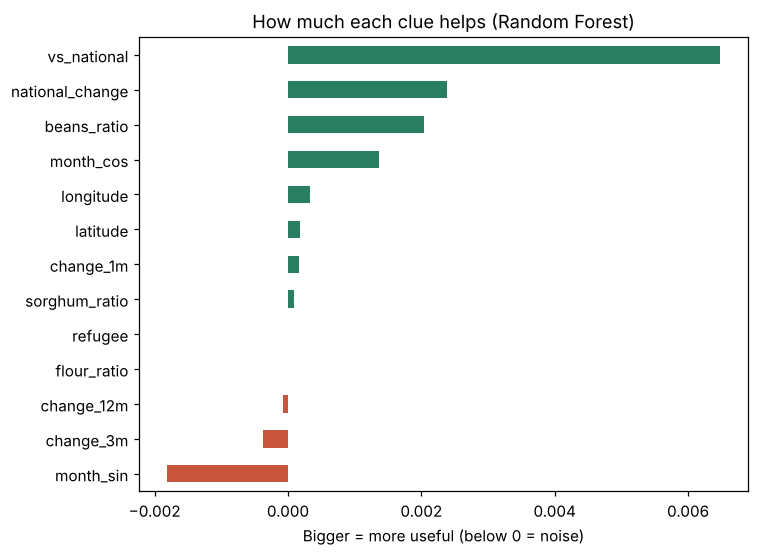

In [14]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(best, val[features], val["target_change"], n_repeats=15,
                             random_state=42, scoring="neg_mean_absolute_error")
importance = pd.Series(imp.importances_mean, index=features).sort_values()
fig, ax = plt.subplots(figsize=(7, 0.32 * len(features) + 1))
importance.plot(kind="barh", ax=ax, color=["#c8553d" if v < 0 else "#2a7f62" for v in importance])
ax.set_title(f"How much each clue helps ({best_name})"); ax.set_xlabel("Bigger = more useful (below 0 = noise)")
plt.tight_layout(); plt.show()

## Step 14B: Did weather help? (fair A/B test)
💡 **Why:** More clues aren't always better. We train the same model **with** and **without** weather. Validation decides.

If Step 7 was skipped, this cell just says so.

In [15]:
if weather_features:
    no_w = [f for f in features if f not in weather_features]
    m_no = HistGradientBoostingRegressor(max_depth=2, learning_rate=0.03, max_iter=200, min_samples_leaf=40,
                                         l2_regularization=1.0, random_state=42).fit(train[no_w], y_tr)
    m_w  = HistGradientBoostingRegressor(max_depth=2, learning_rate=0.03, max_iter=200, min_samples_leaf=40,
                                         l2_regularization=1.0, random_state=42).fit(train[features], y_tr)
    display(pd.DataFrame([grade("Without weather", val, m_no.predict(val[no_w])),
                          grade("With weather", val, m_w.predict(val[features]))]))
else:
    print("No weather data in this run (Step 7 skipped). Run with internet to test it.")

No weather data in this run (Step 7 skipped). Run with internet to test it.


## Step 15: The final exam (run ONCE) 📕
💡 **Why:** The test set (2025–2026) is the closest thing to real life. We only look **after** every choice is made. If you keep tweaking after seeing it, it stops being a fair exam.

In [16]:
final = pd.DataFrame([
    grade("Baseline: same as last month", test, np.zeros(len(test))),
    *[grade(n, test, m.predict(test[features])) for n, m in models.items()],
    grade(f"{best_name} + careful moves ({int(SHRINK*100)}%)", test, SHRINK * best.predict(test[features])),
])
final

,model,MAE,RMSE,R2,direction_right
0,Baseline: same as last month,199.2,290.9,0.497,—
1,Ridge,185.8,259.0,0.601,66%
2,Random Forest,191.9,266.9,0.576,65%
3,Gradient Boosting,187.9,264.1,0.585,69%
4,Random Forest + careful moves (50%),191.9,275.5,0.549,65%


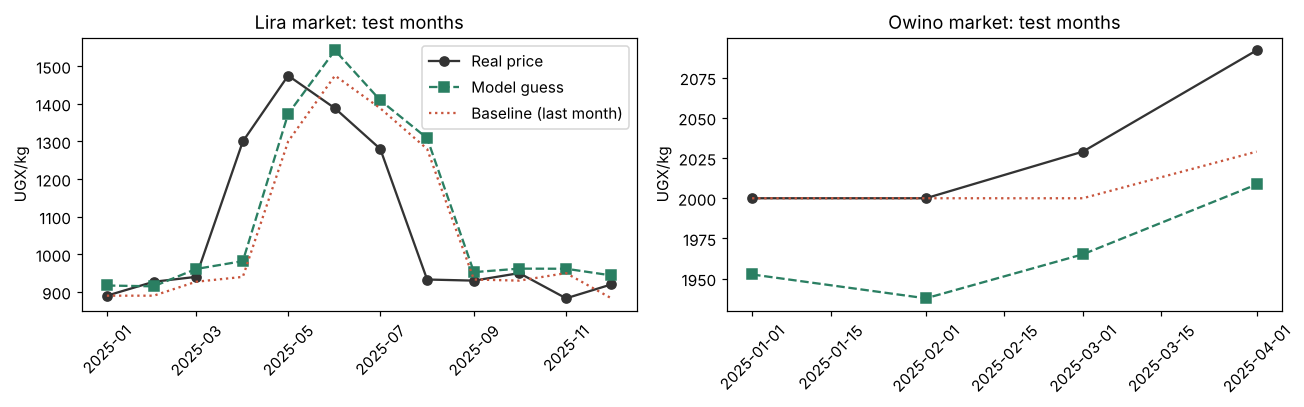

In [17]:
pred = test.assign(predicted=to_price(test, SHRINK * best.predict(test[features])))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, mk in zip(axes, ["Lira", "Owino"]):
    s = pred[pred["market"] == mk]
    ax.plot(s["month"], s["price"], "o-", color="#333", label="Real price")
    ax.plot(s["month"], s["predicted"], "s--", color="#2a7f62", label="Model guess")
    ax.plot(s["month"], s["last_price"], ":", color="#c8553d", label="Baseline (last month)")
    ax.set_title(f"{mk} market: test months"); ax.set_ylabel("UGX/kg"); ax.tick_params(axis="x", rotation=45)
axes[0].legend(); plt.tight_layout(); plt.show()

## Step 16: A price **range**, not just one number 📏
💡 **Why:** One number hides how unsure we are. We train two extra models: one for a **low** guess (10%) and one for a **high** guess (90%). If it works, about **80%** of real prices land inside the range.

✅ **Check:** "coverage" on the test set is close to 80%.
🔧 **If coverage is much lower:** the future is wilder than the past. Widen the range (e.g. 5% and 95%).

In [18]:
lo_model = HistGradientBoostingRegressor(loss="quantile", quantile=0.10, max_depth=2, learning_rate=0.03,
                                         max_iter=200, min_samples_leaf=40, random_state=42).fit(X_tr, y_tr)
hi_model = HistGradientBoostingRegressor(loss="quantile", quantile=0.90, max_depth=2, learning_rate=0.03,
                                         max_iter=200, min_samples_leaf=40, random_state=42).fit(X_tr, y_tr)
low, high = to_price(test, lo_model.predict(test[features])), to_price(test, hi_model.predict(test[features]))
coverage = np.mean((test["price"].values >= low) & (test["price"].values <= high))
print(f"Real price inside the range: {coverage:.0%} of test months (target ≈ 80%)")
print(f"Average range width: ±{np.mean((high - low) / 2):.0f} UGX/kg")

Real price inside the range: 70% of test months (target ≈ 80%)
Average range width: ±245 UGX/kg


## Step 17: Group similar markets (unsupervised) 🧩
💡 **Why:** Unsupervised learning finds groups **without being told the answers**. We describe each market by its price level, how jumpy it is, how strong its seasons are, and where it is. Then **K-means** sorts them into 4 groups.

**Use:** markets in the same group behave alike, so one forecast style can serve the whole group, and a new market can borrow from its group.

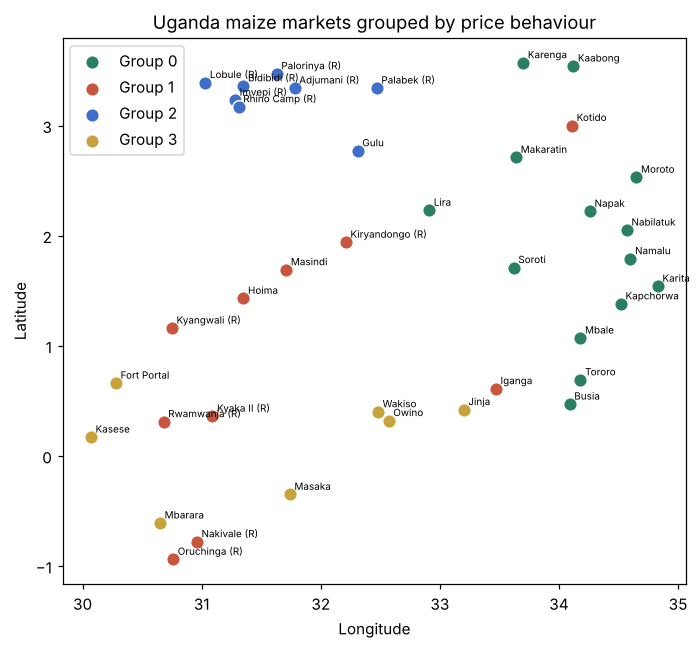

,level,jumpiness,seasonality
group,,,
0,-0.052,0.145,0.090
1,-0.115,0.209,0.165
2,0.142,0.178,0.099
3,0.133,0.138,0.065


In [19]:
from sklearn.cluster import KMeans
recent = data[data["month"] >= "2015-01-01"]
profile = recent.groupby("market").agg(
    level=("vs_national", "mean"),
    jumpiness=("target_change", "std"),
    seasonality=("target_change", lambda s: s.groupby(recent.loc[s.index, "month"].dt.month).mean().std()),
    latitude=("latitude", "first"), longitude=("longitude", "first")).dropna()
Z = StandardScaler().fit_transform(profile)
profile["group"] = KMeans(n_clusters=4, n_init=20, random_state=42).fit_predict(Z)

fig, ax = plt.subplots(figsize=(6.5, 6))
colors = ["#2a7f62", "#c8553d", "#3d6fc8", "#c8a33d"]
for gid, s in profile.groupby("group"):
    ax.scatter(s["longitude"], s["latitude"], s=80, color=colors[gid], label=f"Group {gid}", edgecolor="white")
    for mk, r in s.iterrows():
        ax.annotate(mk.replace(" (refugee settlement)", " (R)"), (r["longitude"], r["latitude"]), fontsize=6.5,
                    xytext=(3, 3), textcoords="offset points")
ax.set_title("Uganda maize markets grouped by price behaviour"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.legend(); plt.tight_layout(); plt.show()
profile.groupby("group")[["level", "jumpiness", "seasonality"]].mean().round(3)

**How to read the table:** `level` above 0 means pricier than the national median. `jumpiness` is how wildly prices move each month. `seasonality` is how strong the yearly wave is.

## Step 18: Flag strange months (anomaly alarm) 🚨
💡 **Why:** Big shocks (drought, conflict, border closures) are what people need warning about. We flag a month as **strange** when its price change is more than 3× that market's normal wobble.

In [20]:
data["wobble"] = data.groupby("market")["target_change"].transform(lambda s: s.rolling(24, min_periods=12).std().shift(1))
data["anomaly"] = data["target_change"].abs() > 3 * data["wobble"]
alarms = data[data["anomaly"]][["month", "market", "last_price", "price", "target_change"]].copy()
alarms["change_%"] = (np.exp(alarms["target_change"]) - 1).mul(100).round(0)
print("Strange months found:", len(alarms), "out of", data["wobble"].notna().sum())
alarms.drop(columns="target_change").sort_values("month").tail(10)

Strange months found: 47 out of 2048


,month,market,last_price,price,change_%
2329,2025-05-01,Mbarara,1569.0,2625.0,67.0
2585,2025-08-01,Namalu,1567.0,1083.0,-31.0
698,2025-08-01,Imvepi (refugee settlement),2446.0,1425.0,-42.0
2941,2025-08-01,Palabek (refugee settlement),2000.0,1259.0,-37.0
1185,2025-09-01,Karenga,1708.0,914.0,-46.0
1273,2025-09-01,Karita,1818.0,1263.0,-31.0
1957,2025-09-01,Makaratin,1950.0,1290.0,-34.0
57,2025-09-01,Adjumani (refugee settlement),1415.0,2257.0,60.0
970,2025-09-01,Kaabong,1706.0,1075.0,-37.0
58,2025-10-01,Adjumani (refugee settlement),2257.0,1288.0,-43.0


## Step 19: Forecast NEXT month for every market 🔮
💡 **Why:** This is what a user of the app would see: a price, a range, and an up/down arrow.

We retrain on **all** data (train + validation + test) so the model knows the newest months, then predict the month after the last price we have.

In [21]:
X_all, y_all = data[features], data["target_change"]
best.fit(X_all, y_all); lo_model.fit(X_all, y_all); hi_model.fit(X_all, y_all)

# Build next month's clues for each market
latest_month = panel.dropna(subset=["price"])["month"].max()
next_rows = []
for mk, s in panel.groupby("market"):
    s = s.set_index("month")
    if latest_month not in s.index or pd.isna(s.loc[latest_month, "price"]): continue
    get = lambda m: s["price"].get(latest_month - pd.DateOffset(months=m), np.nan)
    nxt = latest_month + pd.DateOffset(months=1)
    natn = national.set_index("month")["national_price"]
    row = {"market": mk, "month": nxt, "last_price": get(0),
           "change_1m": np.log(get(0)/get(1)), "change_3m": np.log(get(0)/get(3)), "change_12m": np.log(get(0)/get(12)),
           "vs_national": np.log(get(0)/natn.get(latest_month, np.nan)),
           "national_change": np.log(natn.get(latest_month, np.nan)/natn.get(latest_month - pd.DateOffset(months=1), np.nan)),
           "month_sin": np.sin(2*np.pi*nxt.month/12), "month_cos": np.cos(2*np.pi*nxt.month/12),
           "latitude": s["latitude"].iloc[0], "longitude": s["longitude"].iloc[0], "refugee": int("refugee" in mk)}
    for food in ["flour", "beans", "sorghum"]:
        row[f"{food}_ratio"] = np.log(s[f"{food}_price"].get(latest_month, np.nan) / get(0))
    for f in weather_features:
        k = int(f[-1]) if f[-1].isdigit() else 1
        col = "rain_mm_day" if f.startswith("rain") else "temp_c"
        row[f] = s[col].get(latest_month - pd.DateOffset(months=k-1), np.nan) if f != "rain_vs_last_year" else \
                 s["rain_mm_day"].get(latest_month, np.nan) - s["rain_mm_day"].get(latest_month - pd.DateOffset(months=12), np.nan)
    next_rows.append(row)
nxt = pd.DataFrame(next_rows)
nxt["forecast"] = to_price(nxt, SHRINK * best.predict(nxt[features])).round(-1)
nxt["low"]  = to_price(nxt, lo_model.predict(nxt[features])).round(-1)
nxt["high"] = to_price(nxt, hi_model.predict(nxt[features])).round(-1)
nxt["trend"] = np.where(nxt["forecast"] > nxt["last_price"] * 1.01, "⬆ up",
                np.where(nxt["forecast"] < nxt["last_price"] * 0.99, "⬇ down", "➡ steady"))
print("Last price month:", latest_month.strftime("%B %Y"), "→ forecasting", (latest_month + pd.DateOffset(months=1)).strftime("%B %Y"))
nxt[["market", "last_price", "forecast", "low", "high", "trend"]].sort_values("forecast", ascending=False).reset_index(drop=True)

Last price month: August 2026 → forecasting September 2026


,market,last_price,forecast,low,high,trend
0,Rhino Camp (refugee settlement),2200.0,2130.0,1650.0,2470.0,⬇ down
1,Bidibidi (refugee settlement),1950.0,1880.0,1490.0,2190.0,⬇ down
2,Imvepi (refugee settlement),1825.0,1770.0,1500.0,2060.0,⬇ down
3,Adjumani (refugee settlement),1500.0,1500.0,1260.0,1790.0,➡ steady
4,Palorinya (refugee settlement),1460.0,1440.0,1220.0,1720.0,⬇ down
5,Palabek (refugee settlement),1455.0,1430.0,1220.0,1700.0,⬇ down
6,Oruchinga (refugee settlement),1350.0,1350.0,1090.0,1590.0,➡ steady
7,Nakivale (refugee settlement),1313.0,1330.0,1080.0,1540.0,⬆ up
8,Kyaka II (refugee settlement),1233.0,1280.0,1100.0,1510.0,⬆ up
9,Rwamwanja (refugee settlement),1133.0,1170.0,1010.0,1440.0,⬆ up


## Step 20: Save everything 💾
💡 **Why:** The app's backend (FastAPI) will load these files instead of retraining every time.

In [22]:
import joblib
os.makedirs("outputs", exist_ok=True)
joblib.dump({"model": best, "low": lo_model, "high": hi_model, "features": features, "shrink": SHRINK},
            "outputs/maize_model.joblib")
data.to_csv("outputs/maize_model_table.csv", index=False)
nxt.to_csv("outputs/next_month_forecast.csv", index=False)
profile.to_csv("outputs/market_groups.csv")
print("Saved to outputs/ ✅", sorted(os.listdir("outputs")))

Saved to outputs/ ✅ ['maize_model.joblib', 'maize_model_table.csv', 'market_groups.csv', 'next_month_forecast.csv']


## ✅ Conclusions

**What works**
- A clean, leak-free pipeline: raw WFP data → monthly market table → clues → time-based split → models → forecast.
- The best model beats "same as last month" on unseen data and says **how sure** it is (a price range).
- Unsupervised learning groups markets and flags price shocks.

**Honest limits**
- Maize prices are **noisy**. "Same as last month" is a strong rival, so the improvement is real but modest.
- The model doesn't yet know **why** prices jump (drought, fuel, exchange rate, conflict, border trade).
- About 2,500 usable rows is small. Deep learning (LSTM) needs much more data to beat these models.

**Next steps (one at a time, keep only what lowers validation error)**
1. Rain + temperature (Step 7, NASA POWER), then CHIRPS v3 for sharper rain
2. Fuel price and UGX/USD exchange rate
3. Plant health from satellites (NDVI) and conflict data (ACLED)
4. Kenya, Tanzania, Rwanda: same code, more data, then test on a country the model hasn't seen
5. Wrap `outputs/maize_model.joblib` in a FastAPI `/predict` endpoint, then build the app

**Data source:** World Food Programme, *Uganda – Food Prices*, Humanitarian Data Exchange (data.humdata.org/dataset/wfp-food-prices).